# Project: Cookie Cats A/B Test Analysis

## Goal

**Cookie Cats** is a popular mobile puzzle game. In this experiment, the game developers want to understand how the position of a lock (gate) in the game affects player engagement and retention. So we need to find which gate position is better for player retention.

## Cookie Cats A/B Test – Analysis Plan

In this analysis, we will examine the **Cookie Cats A/B Test dataset**, where two versions of the mobile game were tested:

- `gate_30`: Players encounter a lock at level 30
- `gate_40`: Players encounter a lock at level 40

## Target Metric

We will focus on these metrics to evaluate the experiment:

- `retention_1` (Primary): Whether the user returned to the game 1 day after install (binary)
- `retention_7` (Secondary): Whether the user returned after 7 days (optional)



# Data Analysis

## Import Libraries

- In block below we will import all the necessary libraries and load the dataset.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chisquare
from statsmodels.stats.proportion import proportions_ztest
import seaborn as sns
import numpy as np

plt.style.use('seaborn-v0_8-white')


## Data Exploration

Before conducting statistical tests, we perform exploratory data analysis to better understand the dataset characteristics, such as distributions, group sizes, and potential outliers.

In [2]:
df = pd.read_csv("datasets/cookie_cats.csv")
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


- Check for null values and data types.
- Check unique values in the `Promotion` column.

In [3]:
print(df.info())

print("Game versions:", df['version'].unique(), end="\n\n")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   userid          90189 non-null  int64 
 1   version         90189 non-null  object
 2   sum_gamerounds  90189 non-null  int64 
 3   retention_1     90189 non-null  bool  
 4   retention_7     90189 non-null  bool  
dtypes: bool(2), int64(2), object(1)
memory usage: 2.2+ MB
None
Game versions: ['gate_30' 'gate_40']



In [4]:
df.describe()

,userid,sum_gamerounds
count,9.018900e+04,90189.000000
mean,4.998412e+06,51.872457
std,2.883286e+06,195.050858
min,1.160000e+02,0.000000
25%,2.512230e+06,5.000000
50%,4.995815e+06,16.000000
75%,7.496452e+06,51.000000
max,9.999861e+06,49854.000000


In [5]:
print("Group counts:")
print(df['version'].value_counts(), end="\n\n")

print("Retention 1 rate distribution:")
print(df['retention_1'].value_counts(normalize=True), end="\n\n")

print("Retention 7 rate distribution:")
print(df['retention_7'].value_counts(normalize=True))

Group counts:
version
gate_40    45489
gate_30    44700
Name: count, dtype: int64

Retention 1 rate distribution:
retention_1
False    0.55479
True     0.44521
Name: proportion, dtype: float64

Retention 7 rate distribution:
retention_7
False    0.813935
True     0.186065
Name: proportion, dtype: float64


# A/B Testing

## Sample Ratio Mismatch (SRM) Test

Before analyzing the retention rates, we must confirm that users were **randomly and evenly assigned** to the test groups.

We do this by applying a **chi-square test** to the observed vs expected group counts.

If the p-value is low (typically < 0.05), it suggests that the split between groups is not random, which could bias the results.


### Count users in each group

In [6]:
group_counts = df['version'].value_counts()
observed = group_counts.values
expected = [len(df) / 2] * 2

### Run Chi-Square Test

In [7]:
chi2_stat, p_value = chisquare(f_obs=observed, f_exp=expected)

### Output results

In [8]:
print(f"Observed counts: {observed}")
print(f"Expected counts: {expected}")
print(f"Chi-square statistic: {chi2_stat:.2f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Potential SRM detected – groups may not be balanced.")
else:
    print("No SRM detected – group sizes are balanced.")

Observed counts: [45489 44700]
Expected counts: [45094.5, 45094.5]
Chi-square statistic: 6.90
P-value: 0.0086
Potential SRM detected – groups may not be balanced.


### SRM (Sample Ratio Mismatch) Test – Interpretation

We conducted a **Chi-Square Test** to verify if users were equally split between the two test groups.

**Results:**
- Observed counts: `[45489, 44700]`
- Expected counts: `[45094.5, 45094.5]`
- Chi-square statistic: `6.90`
- p-value: `0.0086`

**Interpretation**:
- Since the p-value is less than 0.05, we conclude that the split between the two groups is **not perfectly balanced**.
- A small **Sample Ratio Mismatch (SRM)** is present.

It's important to interpret final results with this context in mind.

## Visualizing Group Imbalance (SRM)

To better illustrate the **sample ratio mismatch**, we visualize the number of users per test group and overlay a line representing the **expected equal split**.

This helps clearly highlight how many more or fewer users were assigned to each group compared to the ideal 50/50 random assignment.

### Count users in each group

In [9]:
group_counts = df['version'].value_counts().reset_index()
group_counts.columns = ['version', 'count']
expected_count = len(df) / 2

### Plot with expected line and annotations

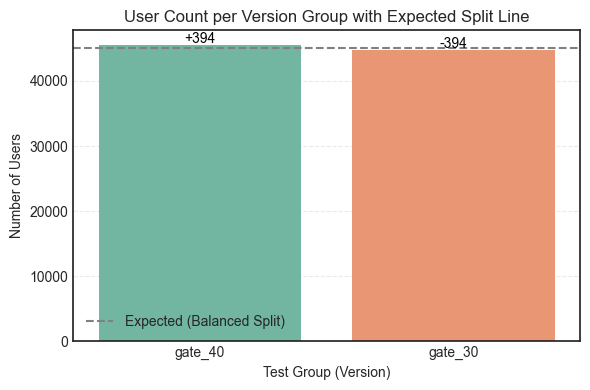

In [10]:
plt.figure(figsize=(6, 4))
sns.barplot(data=group_counts, x='version', y='count', palette='Set2', hue='version')

plt.axhline(expected_count, color='gray', linestyle='--', label='Expected (Balanced Split)')

for index, row in group_counts.iterrows():
    diff = int(row['count'] - expected_count)
    plt.text(index, row['count'] + 300, f"{diff:+}", ha='center', color='black', fontsize=10)

plt.title("User Count per Version Group with Expected Split Line")
plt.ylabel("Number of Users")
plt.xlabel("Test Group (Version)")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

## Statistical Comparison of 1-Day Retention - z-test

We now test whether the difference in 1-day retention (`retention_1`) between the two groups is **statistically significant**.

Since `retention_1` is a binary variable (0 or 1), we can treat it as a **proportion** and apply a **proportions z-test** to compare the two groups.


### Count of retained users (successes) and total users per group

In [11]:
ret1_summary = df.groupby('version')['retention_1'].agg(['sum', 'count'])
successes = ret1_summary['sum'].values
totals = ret1_summary['count'].values

### Perform proportions z-test

In [12]:
z_stat, p_value = proportions_ztest(successes, totals)

### Print results

In [13]:
print(f"Retention 1-Day Rates:")
print(ret1_summary, end="\n\n")

print(f"Z-statistic: {z_stat:.4f}")
print(f"P-value: {p_value:.4f}")

if p_value < 0.05:
    print("Statistically significant difference in 1-day retention.")
else:
    print("No statistically significant difference detected.")

Retention 1-Day Rates:
           sum  count
version              
gate_30  20034  44700
gate_40  20119  45489

Z-statistic: 1.7841
P-value: 0.0744
No statistically significant difference detected.


### Let's visualize z-test rezults

#### Summary data

In [14]:
ret1_summary = df.groupby('version')['retention_1'].agg(['sum', 'count'])
ret1_summary['rate'] = ret1_summary['sum'] / ret1_summary['count']
ret1_summary['ci_low'] = ret1_summary['rate'] - 1.96 * np.sqrt((ret1_summary['rate'] * (1 - ret1_summary['rate'])) / ret1_summary['count'])
ret1_summary['ci_high'] = ret1_summary['rate'] + 1.96 * np.sqrt((ret1_summary['rate'] * (1 - ret1_summary['rate'])) / ret1_summary['count'])

### Visualize

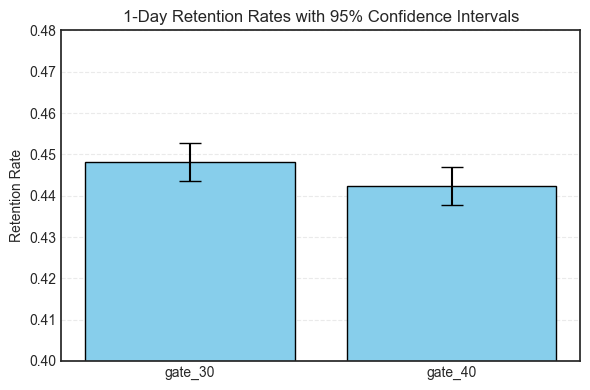

In [15]:
plt.figure(figsize=(6, 4))
plt.bar(ret1_summary.index, ret1_summary['rate'], yerr=[ret1_summary['rate'] - ret1_summary['ci_low'], ret1_summary['ci_high'] - ret1_summary['rate']],
        capsize=8, color='skyblue', edgecolor='black')

plt.title("1-Day Retention Rates with 95% Confidence Intervals")
plt.ylabel("Retention Rate")
plt.ylim(0.40, 0.48)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Interpretation of 1-Day Retention Comparison – Interpretation

We compared 1-day retention (`retention_1`) between the two groups using a **proportions z-test**.

| Group     | Users   | Retained | Retention Rate |
|-----------|---------|----------|----------------|
| `gate_30` | 44,700  | 20,034   | **44.8%**       |
| `gate_40` | 45,489  | 20,119   | **44.2%**       |

- **Z-statistic** = 1.7841
- **P-value** = 0.0744

**Conclusion**:
There is a small difference in retention, but it is **not statistically significant** (p > 0.05).
Thus, we **cannot conclude** that the change in gate position has a meaningful effect on 1-day retention.


## Bootstrap Confidence Intervals for 1-Day Retention Rate Difference

We now apply the **bootstrap method** to estimate the 95% confidence interval for the **difference in 1-day retention** between `gate_30` and `gate_40`.

Bootstrapping helps quantify uncertainty **without assuming normality**.


### Create bootsrap method

In [16]:
def bootstrap_ci(data_a, data_b, n_bootstrap=10000, seed=42):
    np.random.seed(seed)
    boot_diffs = []
    for _ in range(n_bootstrap):
        sample_a = np.random.choice(data_a, size=len(data_a), replace=True)
        sample_b = np.random.choice(data_b, size=len(data_b), replace=True)
        boot_diffs.append(np.mean(sample_a) - np.mean(sample_b))
    lower = np.percentile(boot_diffs, 2.5)
    upper = np.percentile(boot_diffs, 97.5)
    return np.mean(boot_diffs), lower, upper, boot_diffs


### Extract binary data

In [17]:
ret_a = df[df['version'] == 'gate_30']['retention_1'].values
ret_b = df[df['version'] == 'gate_40']['retention_1'].values

### Bootstrap

In [18]:
mean_diff, ci_low, ci_high, boot_diffs = bootstrap_ci(ret_a, ret_b)

### Visualize bootstrap distribution

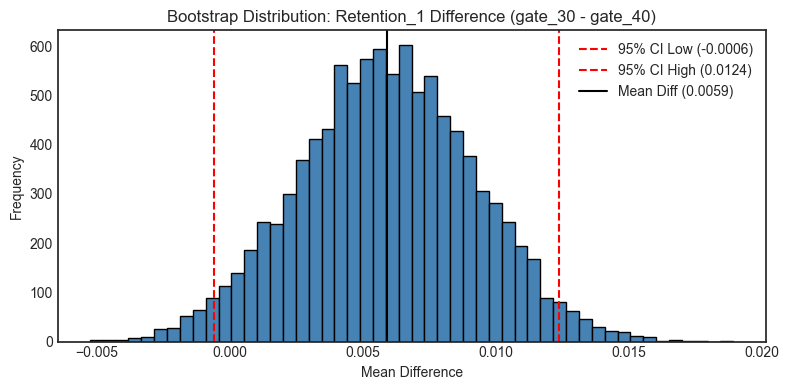

In [19]:
plt.figure(figsize=(8, 4))
plt.hist(boot_diffs, bins=50, color='steelblue', edgecolor='black')
plt.axvline(ci_low, color='red', linestyle='--', label=f'95% CI Low ({ci_low:.4f})')
plt.axvline(ci_high, color='red', linestyle='--', label=f'95% CI High ({ci_high:.4f})')
plt.axvline(mean_diff, color='black', linestyle='-', label=f'Mean Diff ({mean_diff:.4f})')
plt.title("Bootstrap Distribution: Retention_1 Difference (gate_30 - gate_40)")
plt.xlabel("Mean Difference")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

### Interpretaion of Bootstrap Confidence Interval – Retention_1 Difference

This histogram shows the **bootstrap distribution** of the difference in 1-day retention between `gate_30` and `gate_40`.

#### Summary:
- **Mean difference**: `+0.0059` → ≈ **+0.59 percentage points**
- **95% CI**: `[-0.0006, 0.0124]`

**Interpretation**:
- The confidence interval **includes 0**, meaning that the difference is **not statistically significant**.
- This confirms the earlier z-test result: we **cannot reject the null hypothesis**.
- The difference in 1-day retention **could be due to chance**.

Although `gate_30` seems slightly better, there’s **not enough statistical evidence** to confirm that moving the gate improves retention after one day.


## Statistical Comparison of 7-Day Retention - z-test

Next, we compare 7-day retention (`retention_7`) between the two user groups.

This binary metric (0 or 1) represents whether a user returned to the game 7 days after installation.
We'll use a **proportions z-test** to determine if the difference is statistically significant.


### Group retention_7 summary

In [20]:
ret7_summary = df.groupby('version')['retention_7'].agg(['sum', 'count'])
successes_7 = ret7_summary['sum'].values
totals_7 = ret7_summary['count'].values

### Proportions z-test

In [21]:
z_stat_7, p_value_7 = proportions_ztest(successes_7, totals_7)

### Print result

In [22]:
print(f"Retention 7-Day Rates:")
print(ret7_summary, end="\n\n")

print(f"Z-statistic: {z_stat_7:.4f}")
print(f"P-value: {p_value_7:.4f}")

if p_value_7 < 0.05:
    print("Statistically significant difference in 7-day retention.")
else:
    print("No statistically significant difference detected.")

Retention 7-Day Rates:
          sum  count
version             
gate_30  8502  44700
gate_40  8279  45489

Z-statistic: 3.1644
P-value: 0.0016
Statistically significant difference in 7-day retention.


### Interpretation of 7-Day Retention Comparison

We compared 7-day retention (`retention_7`) between the two groups using a **proportions z-test**.

| Group     | Users   | Retained |
|-----------|---------|----------|
| `gate_30` | 44,700  | 8,502    |
| `gate_40` | 45,489  | 8,279    |

- **Z-statistic** = 3.1644
- **P-value** = 0.0016

**Conclusion**:
The difference in 7-day retention is **statistically significant**.
This means the change in gate position **had a measurable effect** on long-term player retention.

- Players in `gate_30` were significantly more likely to return after 7 days than those in `gate_40`.


### Visualization: 7-Day Retention Rates with 95% Confidence Intervals

We visualize the 7-day retention rate for each group along with **95% confidence intervals** using the standard error of proportions.


### Calculate retention rate and CI

In [23]:
ret7_summary = df.groupby('version')['retention_7'].agg(['sum', 'count'])
ret7_summary['rate'] = ret7_summary['sum'] / ret7_summary['count']
ret7_summary['ci_low'] = ret7_summary['rate'] - 1.96 * np.sqrt((ret7_summary['rate'] * (1 - ret7_summary['rate'])) / ret7_summary['count'])
ret7_summary['ci_high'] = ret7_summary['rate'] + 1.96 * np.sqrt((ret7_summary['rate'] * (1 - ret7_summary['rate'])) / ret7_summary['count'])

### Visualize

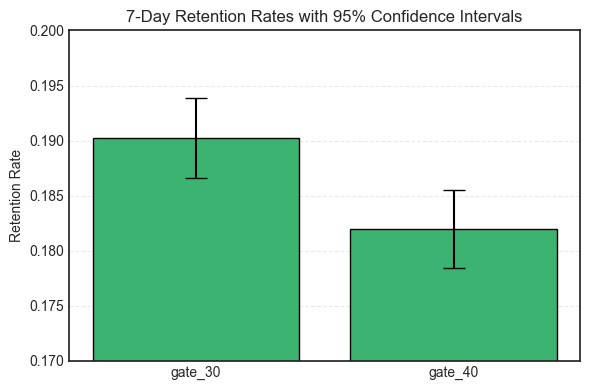

In [24]:
plt.figure(figsize=(6, 4))
plt.bar(ret7_summary.index, ret7_summary['rate'],
        yerr=[ret7_summary['rate'] - ret7_summary['ci_low'], ret7_summary['ci_high'] - ret7_summary['rate']],
        capsize=8, color='mediumseagreen', edgecolor='black')

plt.title("7-Day Retention Rates with 95% Confidence Intervals")
plt.ylabel("Retention Rate")
plt.ylim(0.17, 0.20)
plt.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

### Interpretation: 7-Day Retention with 95% Confidence Intervals

The bar chart shows the **7-day retention rates** for `gate_30` and `gate_40` groups, including **95% confidence intervals**.

### Key Observations:
- `gate_30` has a **higher retention rate** (≈19.0%) compared to `gate_40` (≈18.2%).
- The **confidence intervals do not overlap**, visually confirming a **statistically significant difference**.
- This is consistent with the proportions z-test result (p = 0.0016).

**Conclusion**:
The change in gate position has a **statistically significant impact on long-term player retention**.
Moving the gate earlier in the game (`gate_30`) results in **better player engagement** over the first week.


## Bootstrap Confidence Interval – 7-Day Retention Rate Difference

We now apply the **bootstrap method** to estimate the 95% confidence interval for the **difference in 7-day retention** between `gate_30` and `gate_40`.

This helps validate the statistical difference without assuming normality.


### Prepare data

In [25]:
ret7_a = df[df['version'] == 'gate_30']['retention_7'].values
ret7_b = df[df['version'] == 'gate_40']['retention_7'].values

### Bootstrap

In [26]:
mean_diff, ci_low, ci_high, boot_diffs = bootstrap_ci(ret7_a, ret7_b)

### Visualize

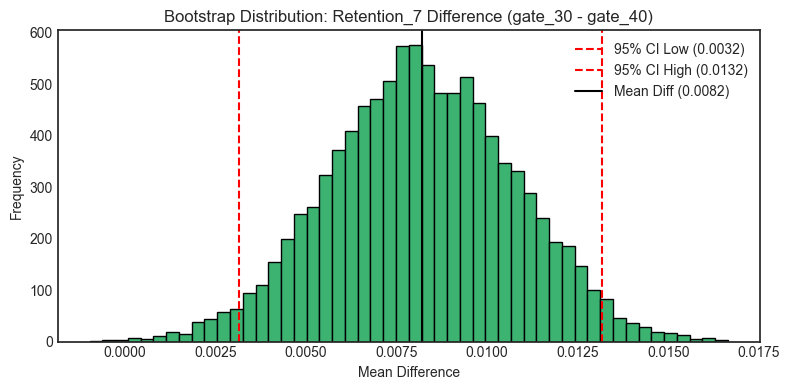

In [27]:
plt.figure(figsize=(8, 4))
plt.hist(boot_diffs, bins=50, color='mediumseagreen', edgecolor='black')
plt.axvline(ci_low, color='red', linestyle='--', label=f'95% CI Low ({ci_low:.4f})')
plt.axvline(ci_high, color='red', linestyle='--', label=f'95% CI High ({ci_high:.4f})')
plt.axvline(mean_diff, color='black', linestyle='-', label=f'Mean Diff ({mean_diff:.4f})')
plt.title("Bootstrap Distribution: Retention_7 Difference (gate_30 - gate_40)")
plt.xlabel("Mean Difference")
plt.ylabel("Frequency")
plt.legend()
plt.tight_layout()
plt.show()

## Bootstrap Confidence Interval – 7-Day Retention Difference

This histogram shows the **bootstrap distribution** of the difference in 7-day retention between `gate_30` and `gate_40`.

### Summary:
- **Mean difference**: `+0.0082` → ≈ **+0.82 percentage points**
- **95% CI**: `[0.0032, 0.0132]`

**Interpretation**:
- The entire confidence interval is **above 0**, indicating a **statistically significant** improvement.
- This confirms that the earlier gate placement (`gate_30`) **significantly increases** player retention after 7 days.
- The result aligns with our proportions z-test and visual CI analysis.

This provides strong evidence that `gate_30` is more effective for long-term engagement.


# Final Recommendation

After analyzing both 1-day and 7-day retention, we summarize our findings below:

## Summary of Findings

| Metric         | Result                                                  |
|----------------|---------------------------------------------------------|
| **Retention 1** | gate_30 slightly higher than gate_40 (≈ +0.6 pp)       |
| **Retention 7** | gate_30 clearly higher than gate_40 (≈ +0.8 pp)        |

- Both analytical and bootstrap confidence intervals for **retention_7** exclude 0.
- **Confidence intervals for retention_1 overlap**, confirming no strong difference.

## Decision:
Based on the statistically significant improvement in **7-day retention**, we recommend:

- **Use the `gate_30` configuration** for improved long-term player retention.

This recommendation is supported by consistent evidence from:
- **Proportions z-tests**
- **Confidence intervals**
- **Bootstrap analysis**
